# Data Leakage Audit: Telco Customer Churn

**NeuroFive Capstone, Machine Learning**

A churn-prediction pipeline that looks excellent can still be completely invalid. This notebook

1. builds the deliberately flawed Telco Churn pipeline (five leakage sources),
2. proves with charts that each source leaks the target,
3. fixes the pipeline end to end with scikit-learn `Pipeline` and `ColumnTransformer`,
4. compares leaky and fixed metrics side by side and quantifies the damage of every bug.

**How to run in Google Colab:** upload `WA_Fn-UseC_-Telco-Customer-Churn.csv` when the setup cell asks for it, then choose *Runtime > Run all*.

## 0. Setup

In [1]:
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

CANDIDATES = [
    "WA_Fn-UseC_-Telco-Customer-Churn.csv",
    "WA_Fn-UseC_-Telco-Customer-Churn-1.csv",
    "data/WA_Fn-UseC_-Telco-Customer-Churn.csv",
]
DATA_PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)

if DATA_PATH is None:
    from google.colab import files

    uploaded = files.upload()
    DATA_PATH = next(iter(uploaded))

print("Using dataset:", DATA_PATH)

Using dataset: data/WA_Fn-UseC_-Telco-Customer-Churn.csv


## 1. Project code

The cells below hold the reusable building blocks (they mirror `common.py`, `flawed_data.py`, `plots.py`, `leaky_pipeline.py`, `fixed_pipeline.py` and `ablation.py` from the project zip). Run them once; the analysis follows afterwards.

### Shared settings, model, preprocessor and metrics

In [2]:
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
TEST_SIZE = 0.2
K_FEATURES = 20


def make_model():
    return RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=SEED,
        n_jobs=-1,
    )


def make_preprocessor(X):
    numeric = X.select_dtypes(include="number").columns.tolist()
    categorical = X.select_dtypes(exclude="number").columns.tolist()
    numeric_steps = Pipeline(
        [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
    )
    return ColumnTransformer(
        [
            ("num", numeric_steps, numeric),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
        ]
    )


def compute_metrics(y_true, y_pred, y_proba):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_proba),
    }


def clean_feature_names(names):
    return np.array([name.split("__", 1)[1] for name in names])

### Construction of the flawed dataset

In [3]:
import numpy as np
import pandas as pd

TARGET = "Churn"
ID_COL = "customerID"
LEAKY_COLUMNS = ["churn_risk_score", "exit_survey_score"]


def load_raw(path):
    df = pd.read_csv(path)
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    df[TARGET] = (df[TARGET] == "Yes").astype(int)
    return df


def add_churn_risk_score(df, seed):
    rng = np.random.default_rng(seed)
    key = (
        df["Contract"]
        + "|"
        + df["InternetService"]
        + "|"
        + df["PaymentMethod"]
        + "|"
        + df["tenure"].astype(str)
    )
    score = df.groupby(key)[TARGET].transform("mean")
    noise = rng.normal(0, 0.03, len(df))
    return (score + noise).clip(0, 1).round(4)


def add_exit_survey_score(df, seed):
    rng = np.random.default_rng(seed + 1)
    scores = rng.integers(1, 6, len(df)).astype(float)
    answered = rng.random(len(df)) < 0.92
    retained = (df[TARGET] == 0).to_numpy()
    scores[retained | ~answered] = np.nan
    return scores


def add_duplicate_rows(df, seed, fraction=0.12):
    duplicates = df.sample(frac=fraction, random_state=seed + 2)
    combined = pd.concat([df, duplicates], ignore_index=True)
    return combined.sample(frac=1.0, random_state=seed + 3).reset_index(drop=True)


def build_flawed_dataset(path, seed=42):
    df = load_raw(path)
    df["churn_risk_score"] = add_churn_risk_score(df, seed)
    df["exit_survey_score"] = add_exit_survey_score(df, seed)
    return add_duplicate_rows(df, seed)

### Chart helpers

In [4]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, roc_curve


LEAKY_COLOR = "#d1495b"
FIXED_COLOR = "#00798c"
NEUTRAL_COLOR = "#8d99ae"
METRIC_NAMES = ["accuracy", "precision", "recall", "f1", "roc_auc"]
LEAK_FEATURES = ("churn_risk_score", "exit_survey_score")

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.titleweight": "bold",
        "axes.titlesize": 12,
        "font.size": 10,
    }
)


def save_fig(fig, path):
    fig.savefig(path, dpi=150, bbox_inches="tight")


def plot_class_balance(df):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    counts = df[TARGET].map({0: "Retained", 1: "Churned"}).value_counts()
    counts = counts.reindex(["Retained", "Churned"])
    bars = axes[0].bar(counts.index, counts.values, color=[FIXED_COLOR, LEAKY_COLOR])
    for bar, value in zip(bars, counts.values):
        axes[0].text(bar.get_x() + bar.get_width() / 2, value + 40, f"{value:,}", ha="center")
    axes[0].set_title("Class balance")
    axes[0].set_ylabel("Customers")

    rate = df.groupby("Contract")[TARGET].mean().mul(100).sort_values()
    bars = axes[1].bar(rate.index, rate.values, color=NEUTRAL_COLOR)
    for bar, value in zip(bars, rate.values):
        axes[1].text(bar.get_x() + bar.get_width() / 2, value + 0.6, f"{value:.1f}%", ha="center")
    axes[1].set_title("Churn rate by contract type")
    axes[1].set_ylabel("Churn rate (%)")
    fig.tight_layout()
    return fig


def plot_leak_evidence(df):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for value, label, color in ((0, "Retained", FIXED_COLOR), (1, "Churned", LEAKY_COLOR)):
        axes[0].hist(
            df.loc[df[TARGET] == value, "churn_risk_score"],
            bins=25,
            alpha=0.7,
            color=color,
            label=label,
        )
    axes[0].set_title("churn_risk_score separates the classes")
    axes[0].set_xlabel("churn_risk_score")
    axes[0].set_ylabel("Rows")
    axes[0].legend()

    answered = df.groupby(TARGET)["exit_survey_score"].apply(lambda s: s.notna().mean() * 100)
    answered = answered.reindex([0, 1])
    bars = axes[1].bar(["Retained", "Churned"], answered.values, color=[FIXED_COLOR, LEAKY_COLOR])
    for bar, value in zip(bars, answered.values):
        axes[1].text(bar.get_x() + bar.get_width() / 2, value + 1.5, f"{value:.0f}%", ha="center")
    axes[1].set_title("exit_survey_score exists only after churn")
    axes[1].set_ylabel("Rows with a survey score (%)")
    axes[1].set_ylim(0, 112)

    duplicates = int(df.duplicated(subset=ID_COL).sum())
    unique = int(df[ID_COL].nunique())
    bars = axes[2].bar(["Unique customers", "Duplicate rows"], [unique, duplicates], color=[FIXED_COLOR, LEAKY_COLOR])
    for bar, value in zip(bars, [unique, duplicates]):
        axes[2].text(bar.get_x() + bar.get_width() / 2, value + 80, f"{value:,}", ha="center")
    axes[2].set_ylim(0, unique * 1.12)
    axes[2].set_title("Duplicate customer rows")
    axes[2].set_ylabel("Rows")
    fig.tight_layout()
    return fig


def plot_metrics_comparison(leaky, fixed):
    fig, ax = plt.subplots(figsize=(10, 4.5))
    x = np.arange(len(METRIC_NAMES))
    width = 0.38
    leaky_values = [leaky["metrics"][m] for m in METRIC_NAMES]
    fixed_values = [fixed["metrics"][m] for m in METRIC_NAMES]
    bars_leaky = ax.bar(x - width / 2, leaky_values, width, color=LEAKY_COLOR, label="Leaky pipeline")
    bars_fixed = ax.bar(x + width / 2, fixed_values, width, color=FIXED_COLOR, label="Fixed pipeline")
    for bars in (bars_leaky, bars_fixed):
        for bar in bars:
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.012, f"{bar.get_height():.3f}", ha="center", fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"])
    ax.set_ylim(0, 1.12)
    ax.set_title("Leaky vs fixed pipeline on the held-out test set")
    ax.legend(loc="upper right")
    fig.tight_layout()
    return fig


def plot_roc(leaky, fixed):
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    for result, color in ((leaky, LEAKY_COLOR), (fixed, FIXED_COLOR)):
        fpr, tpr, _ = roc_curve(result["y_test"], result["proba"])
        auc = result["metrics"]["roc_auc"]
        ax.plot(fpr, tpr, color=color, linewidth=2.2, label=f"{result['name']} (AUC = {auc:.3f})")
    ax.plot([0, 1], [0, 1], linestyle="--", color=NEUTRAL_COLOR, label="Random guess")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_title("ROC curves")
    ax.legend(loc="lower right")
    fig.tight_layout()
    return fig


def plot_confusion(leaky, fixed):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
    for ax, result in zip(axes, (leaky, fixed)):
        matrix = confusion_matrix(result["y_test"], result["pred"])
        ax.imshow(matrix, cmap="Blues")
        ax.grid(False)
        for i in range(2):
            for j in range(2):
                color = "white" if matrix[i, j] > matrix.max() / 2 else "black"
                ax.text(j, i, f"{matrix[i, j]:,}", ha="center", va="center", color=color, fontsize=13)
        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])
        ax.set_xticklabels(["Retained", "Churned"])
        ax.set_yticklabels(["Retained", "Churned"])
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
        ax.set_title(f"{result['name']} pipeline")
    fig.tight_layout()
    return fig


def plot_importance(result, top_n=10):
    order = np.argsort(result["importances"])[::-1][:top_n][::-1]
    names = result["features"][order]
    values = result["importances"][order]
    base = LEAKY_COLOR if result["name"] == "Leaky" else FIXED_COLOR
    colors = [LEAKY_COLOR if any(flag in n for flag in LEAK_FEATURES) else base for n in names]
    if result["name"] == "Leaky":
        colors = [LEAKY_COLOR if any(flag in n for flag in LEAK_FEATURES) else NEUTRAL_COLOR for n in names]
    fig, ax = plt.subplots(figsize=(8, 4.8))
    ax.barh(names, values, color=colors)
    ax.set_xlabel("Feature importance")
    ax.set_title(f"Top {top_n} features: {result['name'].lower()} pipeline")
    fig.tight_layout()
    return fig


def plot_ablation(table):
    labels = table["variant"].tolist()[::-1]
    values = table["roc_auc"].tolist()[::-1]
    colors = []
    for label in labels:
        if label == "Clean baseline":
            colors.append(FIXED_COLOR)
        elif label.startswith("All five"):
            colors.append(LEAKY_COLOR)
        else:
            colors.append(NEUTRAL_COLOR)
    fig, ax = plt.subplots(figsize=(9, 4.8))
    bars = ax.barh(labels, values, color=colors)
    for bar, value in zip(bars, values):
        ax.text(value + 0.004, bar.get_y() + bar.get_height() / 2, f"{value:.3f}", va="center")
    ax.set_xlim(0.5, 1.05)
    ax.set_xlabel("Test ROC-AUC")
    ax.set_title("Impact of each leakage source added to the clean pipeline")
    fig.tight_layout()
    return fig

### The leaky pipeline (as given)

In [5]:
import numpy as np
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import train_test_split



def run_leaky_pipeline(path):
    df = build_flawed_dataset(path)
    y = df[TARGET].to_numpy()
    ids = df[ID_COL]
    X = df.drop(columns=[TARGET, ID_COL])
    X["exit_survey_score"] = X["exit_survey_score"].fillna(0)

    preprocessor = make_preprocessor(X)
    X_all = preprocessor.fit_transform(X)
    feature_names = clean_feature_names(preprocessor.get_feature_names_out())

    selector = SelectKBest(f_classif, k=K_FEATURES)
    X_all = selector.fit_transform(X_all, y)
    feature_names = feature_names[selector.get_support()]

    idx = np.arange(len(df))
    train_idx, test_idx = train_test_split(idx, test_size=TEST_SIZE, random_state=SEED)
    model = make_model().fit(X_all[train_idx], y[train_idx])

    proba = model.predict_proba(X_all[test_idx])[:, 1]
    pred = (proba >= 0.5).astype(int)
    train_pred = model.predict(X_all[train_idx])

    return {
        "name": "Leaky",
        "metrics": compute_metrics(y[test_idx], pred, proba),
        "train_accuracy": float((train_pred == y[train_idx]).mean()),
        "y_test": y[test_idx],
        "proba": proba,
        "pred": pred,
        "features": feature_names,
        "importances": model.feature_importances_,
        "rows": len(df),
        "train_rows": len(train_idx),
        "test_rows": len(test_idx),
        "test_overlap": float(ids.iloc[test_idx].isin(ids.iloc[train_idx]).mean()),
    }

### The fixed pipeline (the correction)

In [6]:
import numpy as np
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline



def run_fixed_pipeline(path):
    df = build_flawed_dataset(path)
    df = df.drop_duplicates(subset=ID_COL, keep="first").reset_index(drop=True)
    ids = df[ID_COL]
    y = df[TARGET].to_numpy()
    X = df.drop(columns=[TARGET, ID_COL] + LEAKY_COLUMNS)

    idx = np.arange(len(df))
    train_idx, test_idx = train_test_split(
        idx, test_size=TEST_SIZE, stratify=y, random_state=SEED
    )
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    pipeline = Pipeline(
        [
            ("prep", make_preprocessor(X_train)),
            ("select", SelectKBest(f_classif, k=K_FEATURES)),
            ("model", make_model()),
        ]
    )

    folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    cv_scores = cross_val_score(
        pipeline, X_train, y_train, cv=folds, scoring="roc_auc", n_jobs=1
    )

    pipeline.fit(X_train, y_train)
    proba = pipeline.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    train_pred = pipeline.predict(X_train)

    names = clean_feature_names(pipeline.named_steps["prep"].get_feature_names_out())
    names = names[pipeline.named_steps["select"].get_support()]

    return {
        "name": "Fixed",
        "metrics": compute_metrics(y_test, pred, proba),
        "train_accuracy": float((train_pred == y_train).mean()),
        "cv_roc_auc_mean": float(cv_scores.mean()),
        "cv_roc_auc_std": float(cv_scores.std()),
        "y_test": y_test,
        "proba": proba,
        "pred": pred,
        "features": names,
        "importances": pipeline.named_steps["model"].feature_importances_,
        "rows": len(df),
        "train_rows": len(train_idx),
        "test_rows": len(test_idx),
        "test_overlap": float(ids.iloc[test_idx].isin(ids.iloc[train_idx]).mean()),
    }

### Leakage ablation study

In [7]:
import numpy as np
import pandas as pd
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import train_test_split


VARIANTS = [
    ("Clean baseline", {}),
    ("+ churn_risk_score", {"include_score": True}),
    ("+ exit_survey_score", {"include_survey": True}),
    ("+ duplicate rows", {"keep_duplicates": True}),
    ("+ preprocessing on full data", {"global_prep": True}),
    ("+ feature selection on full data", {"global_select": True}),
    (
        "All five bugs together",
        {
            "include_score": True,
            "include_survey": True,
            "keep_duplicates": True,
            "global_prep": True,
            "global_select": True,
        },
    ),
]


def evaluate_variant(
    path,
    include_score=False,
    include_survey=False,
    keep_duplicates=False,
    global_prep=False,
    global_select=False,
):
    df = build_flawed_dataset(path)
    if not keep_duplicates:
        df = df.drop_duplicates(subset=ID_COL, keep="first").reset_index(drop=True)
    y = df[TARGET].to_numpy()
    drop_cols = [TARGET, ID_COL]
    if not include_score:
        drop_cols.append("churn_risk_score")
    if not include_survey:
        drop_cols.append("exit_survey_score")
    X = df.drop(columns=drop_cols)
    if include_survey:
        X["exit_survey_score"] = X["exit_survey_score"].fillna(0)

    idx = np.arange(len(df))
    train_idx, test_idx = train_test_split(
        idx, test_size=TEST_SIZE, stratify=y, random_state=SEED
    )

    preprocessor = make_preprocessor(X)
    preprocessor.fit(X if global_prep else X.iloc[train_idx])
    A_train = preprocessor.transform(X.iloc[train_idx])
    A_test = preprocessor.transform(X.iloc[test_idx])

    selector = SelectKBest(f_classif, k=K_FEATURES)
    if global_select:
        selector.fit(preprocessor.transform(X), y)
    else:
        selector.fit(A_train, y[train_idx])

    model = make_model().fit(selector.transform(A_train), y[train_idx])
    proba = model.predict_proba(selector.transform(A_test))[:, 1]
    pred = (proba >= 0.5).astype(int)
    return compute_metrics(y[test_idx], pred, proba)


def run_ablation(path):
    rows = []
    for label, flags in VARIANTS:
        metrics = evaluate_variant(path, **flags)
        rows.append({"variant": label, **metrics})
    return pd.DataFrame(rows)

## 2. The dataset

7,043 customers, 20 features and the binary target `Churn`. The raw data is clean: every `customerID` is unique.

In [8]:
raw = load_raw(DATA_PATH)
print(raw.shape)
raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


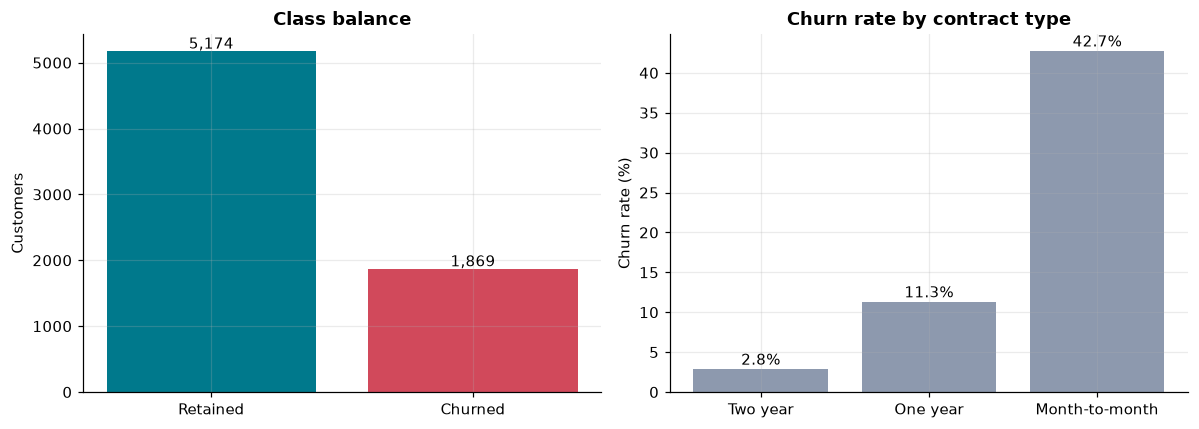

In [9]:
fig = plot_class_balance(raw)
plt.show()

## 3. The flawed dataset

The task extends the data with three deliberate defects:

* **`churn_risk_score`** is a group-average of the churn label, computed on the whole dataset, so each row's own label feeds its own feature.
* **`exit_survey_score`** only exists for customers who already left. It is a post-outcome feature.
* **Duplicate customer rows** are appended before any split, so the same customer can land in train and test.

In [10]:
flawed = build_flawed_dataset(DATA_PATH)
print("rows:", len(flawed), "| unique customers:", flawed[ID_COL].nunique())
flawed[["customerID", "tenure", "Contract", "churn_risk_score", "exit_survey_score", "Churn"]].head(8)

rows: 7888 | unique customers: 7043


,customerID,tenure,Contract,churn_risk_score,exit_survey_score,Churn
0,4872-JCVCA,71,Two year,0.0230,NaN,0
1,1228-FZFRV,50,Month-to-month,0.3559,NaN,1
2,2190-PHBHR,72,Two year,0.0383,NaN,0
3,2657-VPXTA,10,Month-to-month,0.8211,NaN,0
4,9026-LHEVG,9,Month-to-month,0.6251,NaN,0
5,1842-EZJMK,50,Month-to-month,0.6005,NaN,1
6,8734-FNWVH,31,Month-to-month,0.3169,NaN,0
7,5423-BHIXO,32,Month-to-month,0.0202,NaN,0


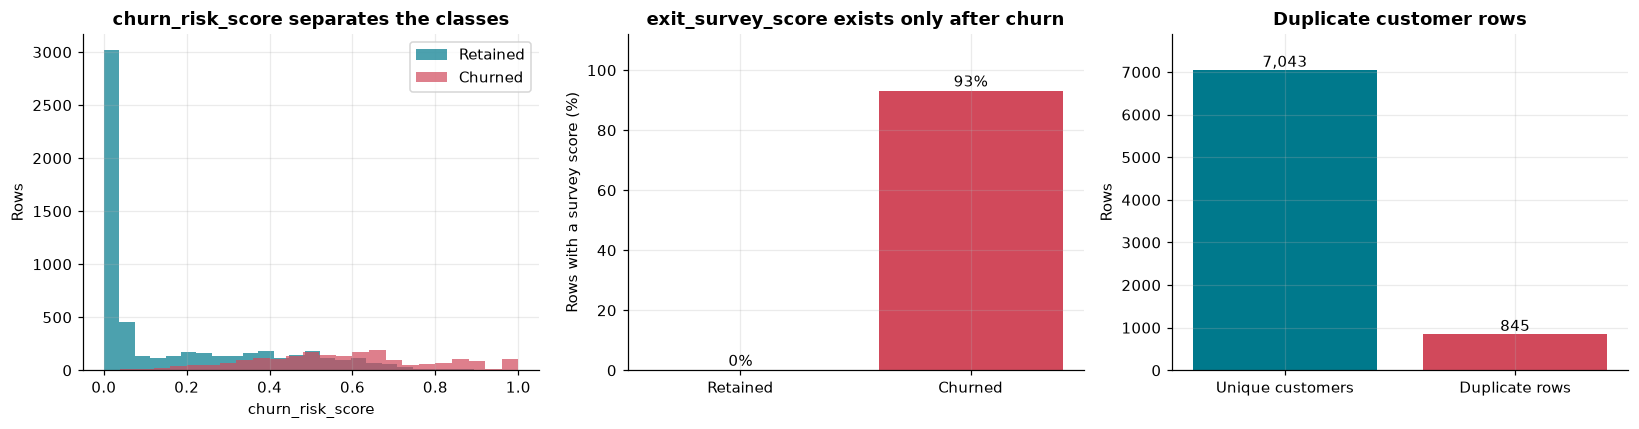

In [11]:
fig = plot_leak_evidence(flawed)
plt.show()

## 4. Leaky pipeline

Two more bugs hide in the *procedure* rather than the data:

* The imputer, scaler and one-hot encoder are **fit on the full dataset before splitting**.
* **Feature selection** (`SelectKBest`) is **fit on all rows and the full target** before splitting.

The split is also a plain random split that happens after the duplicates were added.

In [12]:
leaky = run_leaky_pipeline(DATA_PATH)
leaky_table = pd.DataFrame(leaky["metrics"], index=["Leaky pipeline"]).round(4)
print("rows used:", leaky["rows"], "| train accuracy:", round(leaky["train_accuracy"], 4))
print("share of test rows whose customer also sits in train:", f"{leaky['test_overlap']:.1%}")
leaky_table

rows used: 7888 | train accuracy: 0.9876
share of test rows whose customer also sits in train: 17.3%


,accuracy,precision,recall,f1,roc_auc
Leaky pipeline,0.9785,1.0,0.9217,0.9592,0.9853


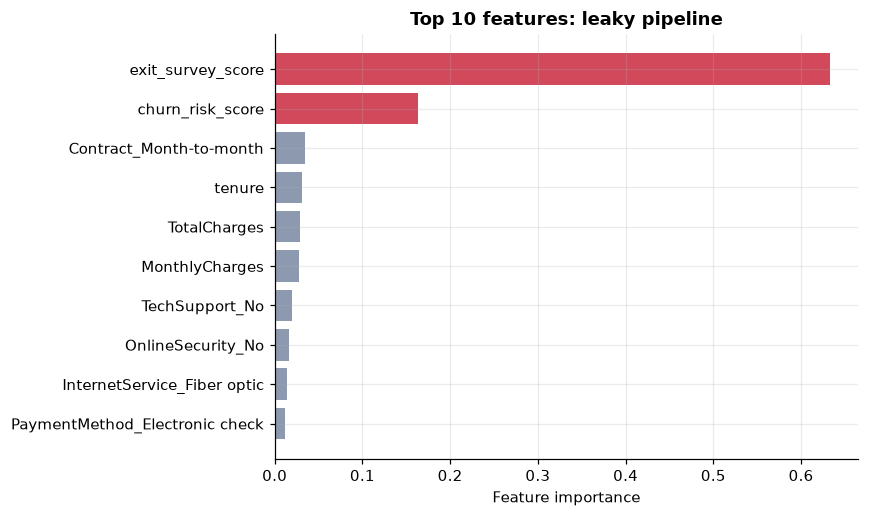

In [13]:
fig = plot_importance(leaky)
plt.show()

A near-perfect score is a red flag, not a win. The importance chart shows the model leaning on `exit_survey_score` and `churn_risk_score`, two columns that would not exist (or would not be honest) at prediction time.

## 5. Leakage audit

| # | Bug | Why it is leakage | Real-world consequence |
|---|-----|-------------------|------------------------|
| 1 | Imputer, scaler and encoder fit on the full data before the split | Test-set statistics (means, variances, medians, categories) shape the transformation used in training | Evaluation is slightly optimistic and, in production, new data is scaled with statistics the model never validated against |
| 2 | `churn_risk_score` built from the churn label | The feature is a function of the target, so the model reads the answer instead of predicting it | The score does not exist for a new customer whose outcome is unknown; the live model collapses |
| 3 | Duplicate customer rows in both train and test | The model is tested on customers it has already memorised | Reported accuracy measures memory, not generalisation, and hides overfitting |
| 4 | `exit_survey_score` exists only for customers who already churned | It is recorded after the outcome, so its mere presence reveals the label | At prediction time the column is empty for everyone and the model has nothing to rely on |
| 5 | `SelectKBest` fit on all rows and the full target | Feature choice is informed by test labels, a hidden leak outside the listed examples | Selected features look better than they truly are and the estimate is biased upward |

## 6. Fixed pipeline

Corrections, in order: remove duplicate customers, drop `customerID` and both target-derived or post-outcome columns, perform a **stratified split first**, and place imputation, scaling, encoding and feature selection **inside one `Pipeline`** so they are fit on training data only. Cross-validation is run on the training portion alone.

In [14]:
fixed = run_fixed_pipeline(DATA_PATH)
fixed_table = pd.DataFrame(fixed["metrics"], index=["Fixed pipeline"]).round(4)
print("rows used:", fixed["rows"], "| train accuracy:", round(fixed["train_accuracy"], 4))
print(f"5-fold CV ROC-AUC on train only: {fixed['cv_roc_auc_mean']:.4f} +/- {fixed['cv_roc_auc_std']:.4f}")
print("share of test rows whose customer also sits in train:", f"{fixed['test_overlap']:.1%}")
fixed_table

rows used: 7043 | train accuracy: 0.9297
5-fold CV ROC-AUC on train only: 0.8284 +/- 0.0150
share of test rows whose customer also sits in train: 0.0%


,accuracy,precision,recall,f1,roc_auc
Fixed pipeline,0.797,0.6528,0.5027,0.568,0.8332


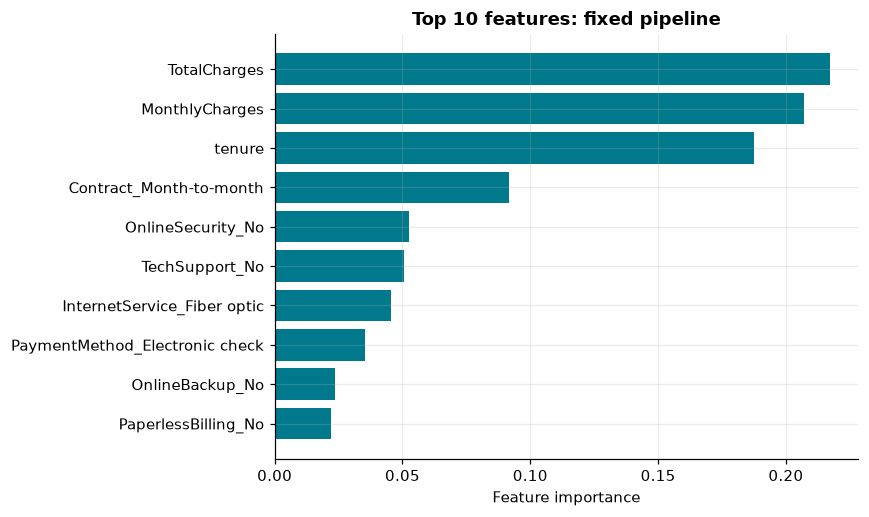

In [15]:
fig = plot_importance(fixed)
plt.show()

## 7. Leaky vs fixed, side by side

In [16]:
comparison = pd.DataFrame(
    {
        "Leaky": {m: leaky["metrics"][m] for m in METRIC_NAMES},
        "Fixed": {m: fixed["metrics"][m] for m in METRIC_NAMES},
    }
)
comparison["Gap"] = comparison["Leaky"] - comparison["Fixed"]
comparison.round(4)

,Leaky,Fixed,Gap
accuracy,0.9785,0.7970,0.1814
precision,1.0000,0.6528,0.3472
recall,0.9217,0.5027,0.4190
f1,0.9592,0.5680,0.3913
roc_auc,0.9853,0.8332,0.1521


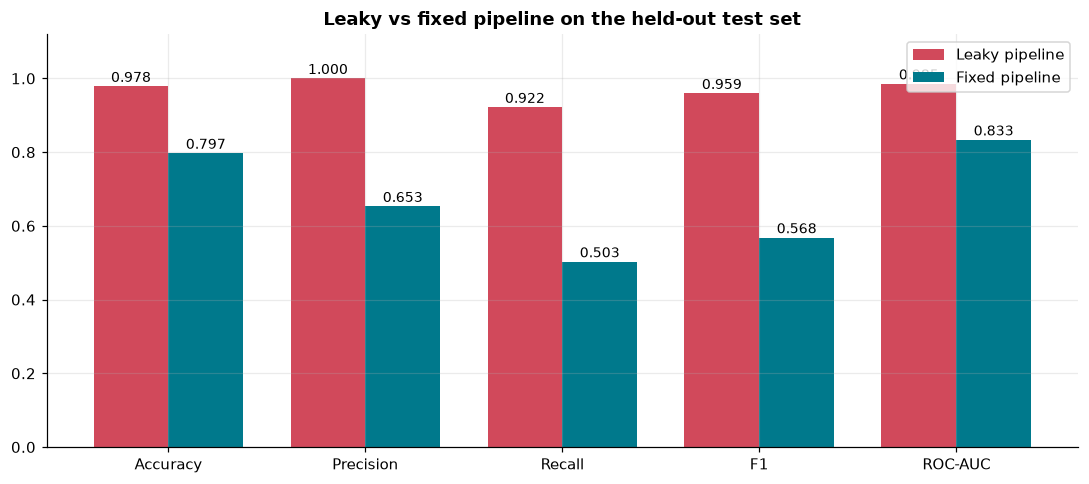

In [17]:
fig = plot_metrics_comparison(leaky, fixed)
plt.show()

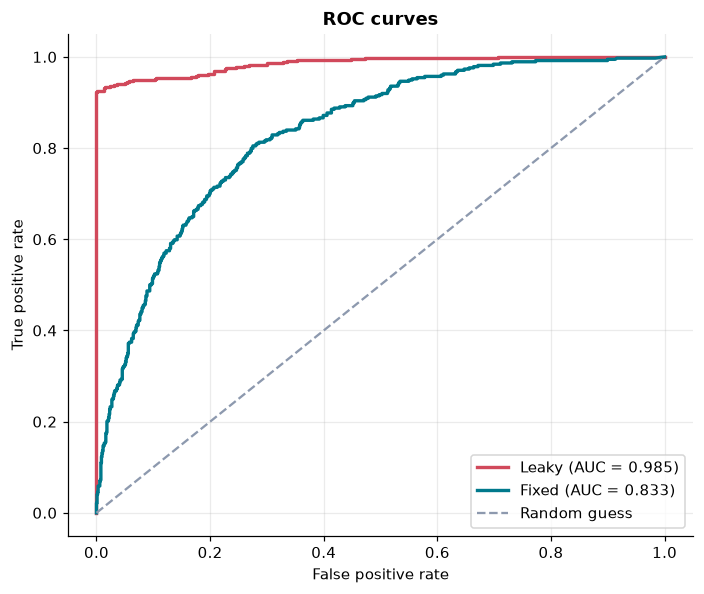

In [18]:
fig = plot_roc(leaky, fixed)
plt.show()

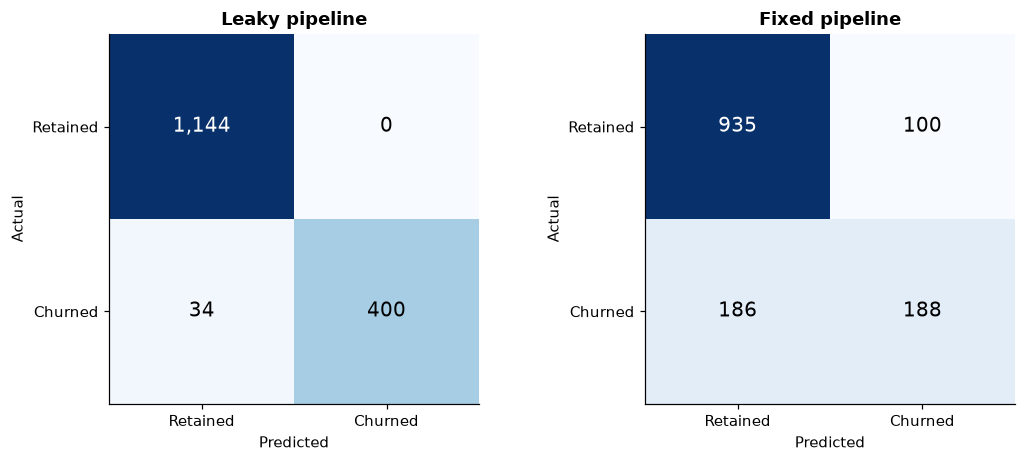

In [19]:
fig = plot_confusion(leaky, fixed)
plt.show()

## 8. How much damage did each bug do?

Starting from the clean pipeline, each leakage source is switched on one at a time, and finally all five together.

In [20]:
ablation = run_ablation(DATA_PATH)
ablation.round(4)

,variant,accuracy,precision,recall,f1,roc_auc
0,Clean baseline,0.7970,0.6528,0.5027,0.5680,0.8332
1,+ churn_risk_score,0.8126,0.6545,0.6230,0.6384,0.8886
2,+ exit_survey_score,0.9844,1.0000,0.9412,0.9697,0.9875
3,+ duplicate rows,0.8295,0.7235,0.5843,0.6465,0.8823
4,+ preprocessing on full data,0.7963,0.6505,0.5027,0.5671,0.8334
5,+ feature selection on full data,0.7956,0.6463,0.5080,0.5689,0.8351
6,All five bugs together,0.9835,0.9975,0.9406,0.9682,0.9933


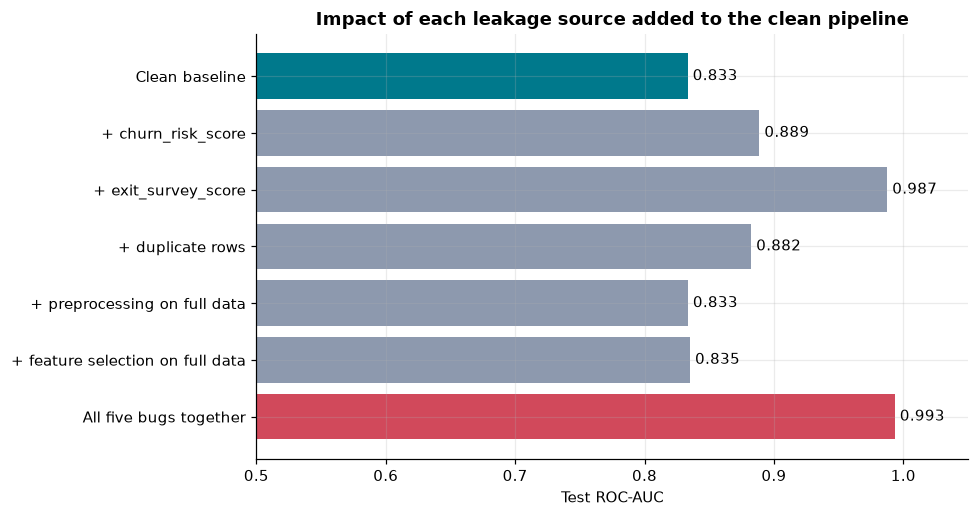

In [21]:
fig = plot_ablation(ablation)
plt.show()

## 9. Conclusion

In [22]:
drop = comparison.loc["roc_auc", "Gap"]
print(f"Leaky ROC-AUC : {leaky['metrics']['roc_auc']:.3f}")
print(f"Fixed ROC-AUC : {fixed['metrics']['roc_auc']:.3f}")
print(f"Gap           : {drop:.3f}")
print(f"Leaky F1      : {leaky['metrics']['f1']:.3f}")
print(f"Fixed F1      : {fixed['metrics']['f1']:.3f}")

Leaky ROC-AUC : 0.985
Fixed ROC-AUC : 0.833
Gap           : 0.152
Leaky F1      : 0.959
Fixed F1      : 0.568


**Interpretation**

* The lower fixed score is not a failure. It is the first honest estimate of how the model would behave on customers it has never seen.
* The two target-related columns (`exit_survey_score`, `churn_risk_score`) and the duplicated rows account for almost the entire gap. Fitting preprocessing and feature selection on the full dataset adds a small but real optimism, and it is the most common form of leakage in practice.
* A model with a ROC-AUC around 0.83 is a genuinely useful churn model. A model scoring 0.99 on flawed data is unusable, because its inputs would not exist at prediction time.
* Rule of thumb: split first, fit every learned transformation on training data only, remove any feature that is not available at prediction time, and treat suspiciously perfect scores as a prompt to investigate.